# 04 · Demand forecast

Monthly units for 16 categories x 3 channels = 48 series. Three methods, tested on 5 rolling backtests.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from utils import *

lines = load_lines()
lines["month"] = lines["order_date"].dt.to_period("M").dt.to_timestamp()
lines = lines[(lines["month"] >= "2018-11-01") & (lines["month"] <= "2026-09-01")]   # drop the 2 partial months

In [2]:
monthly = lines.groupby(["category_en", "sales_channel", "month"])["quantity"].sum()

# add zero months so every series has all 95 months
full = pd.MultiIndex.from_product([lines["category_en"].unique(), lines["sales_channel"].unique(),
                                   pd.date_range("2018-11-01", "2026-09-01", freq="MS")],
                                  names=["category_en", "sales_channel", "month"])
monthly = monthly.reindex(full, fill_value=0).reset_index()
monthly["key"] = monthly["category_en"] + "|" + monthly["sales_channel"]
monthly = monthly.sort_values(["key", "month"]).reset_index(drop=True)
print(monthly["key"].nunique(), "series")

48 series


## Features

In [3]:
FEATURES = ["lag1", "lag2", "lag3", "lag12", "ma3", "ma12", "yoy", "month_num", "category", "channel"]


def add_features(df):
    df = df.copy()
    g = df.groupby("key")["quantity"]
    for lag in [1, 2, 3, 12]:
        df[f"lag{lag}"] = g.shift(lag)
    df["ma3"] = g.transform(lambda s: s.shift(1).rolling(3).mean())
    df["ma12"] = g.transform(lambda s: s.shift(1).rolling(12).mean())
    df["yoy"] = df["ma3"] / g.transform(lambda s: s.shift(13).rolling(3).mean())   # recent growth vs last year
    df["month_num"] = df["month"].dt.month
    df["category"] = df["category_en"].astype("category")
    df["channel"] = df["sales_channel"].astype("category")
    return df

## The three methods

In [4]:
def forecast(cutoff, horizon=3):
    history = monthly[monthly["month"] < cutoff].copy()
    future = pd.date_range(cutoff, periods=horizon, freq="MS")
    table = history.pivot_table(index="key", columns="month", values="quantity")

    # 1. average of the last 3 months
    moving_avg = pd.DataFrame({m: table.iloc[:, -3:].mean(axis=1) for m in future})

    # 2. same month last year x recent growth
    growth = (table.iloc[:, -3:].sum(axis=1) / table.iloc[:, -15:-12].sum(axis=1).replace(0, np.nan)).clip(0.5, 2).fillna(1)
    seasonal = pd.DataFrame({m: table[m - pd.DateOffset(years=1)] * growth for m in future})

    # 3. LightGBM on all series together, one month at a time
    train = add_features(history).dropna(subset=["lag12", "yoy"])
    model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=8,
                              subsample=0.9, subsample_freq=1, random_state=7, verbose=-1)
    model.fit(train[FEATURES], np.log1p(train["quantity"]))

    preds = {}
    for m in future:
        new = history[history["month"] == history["month"].max()][["category_en", "sales_channel", "key"]].copy()
        new["month"] = m
        new["quantity"] = np.nan
        history = pd.concat([history, new], ignore_index=True)
        rows = add_features(history)
        rows = rows[rows["month"] == m]
        p = np.clip(np.expm1(model.predict(rows[FEATURES])), 0, None)
        history.loc[history["month"] == m, "quantity"] = p
        preds[m] = pd.Series(p, index=rows["key"].values)

    return {"Moving average": moving_avg, "Seasonal naive": seasonal, "LightGBM": pd.DataFrame(preds)}, model

## Backtest

WAPE = total absolute error / total actual units.

In [5]:
results = []
for cutoff in ["2025-07-01", "2025-10-01", "2026-01-01", "2026-04-01", "2026-07-01"]:
    fc, _ = forecast(pd.Timestamp(cutoff))
    months = fc["LightGBM"].columns
    actual = monthly[monthly["month"].isin(months)].pivot_table(index="key", columns="month", values="quantity")
    for method, f in fc.items():
        f = f.reindex(actual.index).fillna(0)
        results.append({"cutoff": cutoff, "method": method,
                        "wape": np.abs(actual.values - f.values).sum() / actual.values.sum(),
                        "bias": f.values.sum() / actual.values.sum() - 1})

results = pd.DataFrame(results)
summary = results.groupby("method")[["wape", "bias"]].mean().sort_values("wape", ascending=False)
summary.style.format("{:.1%}")

,wape,bias
method,,
Moving average,13.0%,0.5%
Seasonal naive,11.4%,2.1%
LightGBM,9.1%,-0.2%


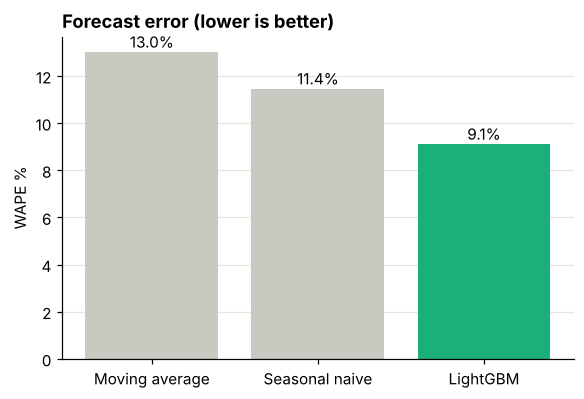

In [6]:
plt.figure(figsize=(6, 3.8))
plt.bar(summary.index, summary["wape"] * 100, color=[GREY, GREY, GREEN])
for i, v in enumerate(summary["wape"] * 100):
    plt.text(i, v + 0.2, f"{v:.1f}%", ha="center")
plt.ylabel("WAPE %")
plt.title("Forecast error (lower is better)")
save("04_backtest")
plt.show()

## Forecast: Oct 2026 to Mar 2027

In [7]:
fc, model = forecast(pd.Timestamp("2026-10-01"), horizon=6)
next6 = fc["LightGBM"]
total = next6.sum()
last_year = monthly[(monthly["month"] >= "2025-10-01") & (monthly["month"] < "2026-04-01")]["quantity"].sum()
print(total.round(0))
print(f"Next 6 months: {total.sum():,.0f} units ({total.sum() / last_year - 1:+.1%} vs same months last year)")

2026-10-01    49773.0
2026-11-01    61307.0
2026-12-01    63183.0
2027-01-01    54998.0
2027-02-01    49826.0
2027-03-01    59272.0
dtype: float64
Next 6 months: 338,360 units (+8.5% vs same months last year)


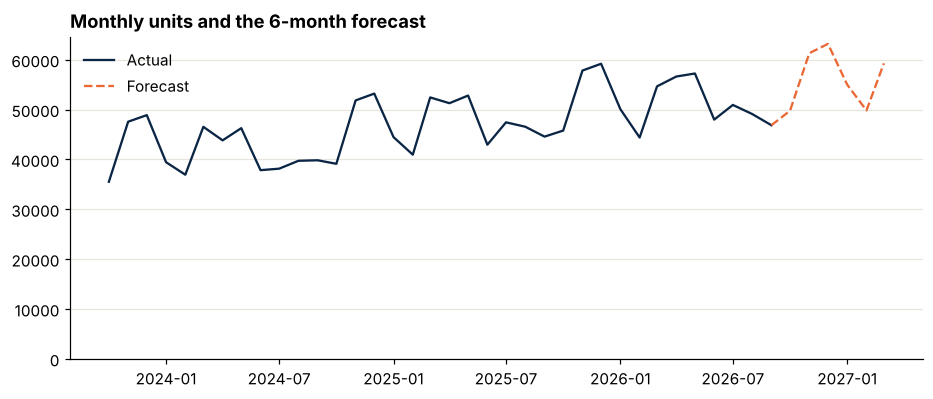

In [8]:
history = monthly.groupby("month")["quantity"].sum()["2023-10-01":]
plt.figure(figsize=(10, 3.8))
plt.plot(history.index, history.values, color=NAVY, label="Actual")
plt.plot([history.index[-1]] + list(total.index), [history.iloc[-1]] + list(total.values), "--", color=ORANGE, label="Forecast")
plt.ylim(0)
plt.title("Monthly units and the 6-month forecast")
plt.legend()
save("04_forecast")
plt.show()

In [9]:
by_category = next6.groupby(next6.index.str.split("|").str[0]).sum().sum(axis=1).sort_values(ascending=False)
by_category.round(0).to_frame("units next 6 months")

,units next 6 months
Socks,83786.0
Men tops,46075.0
Men boxers,38617.0
Women tops,35289.0
Kids underwear,30065.0
Men underwear,20006.0
Girls pajamas,16842.0
Boys pajamas,16140.0
Women bras,15010.0
Home textiles,9688.0


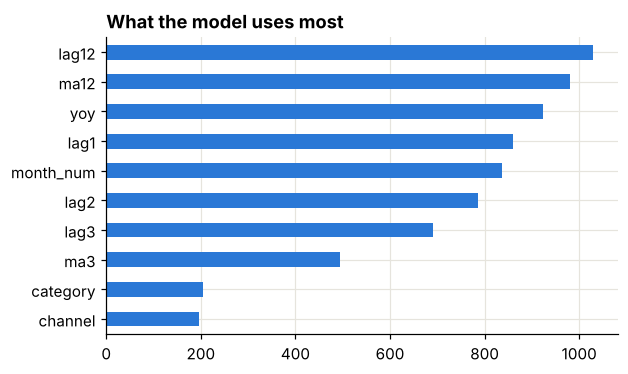

In [10]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(color=BLUE, figsize=(6, 3.5), title="What the model uses most")
plt.show()

**Summary:** LightGBM error ~9% vs 13% for a moving average. Next 6 months: ~338K units (+8.5%).
With 26 months of stock already on hand, this should drive rebalancing more than new buying.